In [1]:
import yaml, re, pandas as pd, os
os.makedirs("../outputs/tables", exist_ok=True)
with open("../configs/prereg.yaml", encoding="utf-8") as f:
    P = yaml.safe_load(f)

status = {
 "epsilon_loss_grid": "Superseded by amendment 1: [0.005, 0.01, 0.02] (the original grid certified no hospital)",
 "delta_calibration_grid": "Unchanged; headline pairs (eps, delta) fixed in amendment 5",
 "final_seeds": "Seed 100 became exploratory (amendment 2). Analyses used 101-104, then 105-109 (amendment 4) and 110-114 (amendment 5); see seed ledger",
 "candidates_local_to_federated": "Superseded by amendment 5: blends 0.25, 0.5, 0.75, 1.0 clipped to local +/- 0.05; local is the fallback",
 "group_testable_rule": "Superseded by amendment 5: tested when >= 20 training deaths in the hospital-group cell",
 "min_hospital_deaths_cutoffs": "Only the 100-death cutoff (126 hospitals) was used in experiments; 50 and 200 appear in the power table only",
 "primary_model": "Unchanged for the main analysis; MLP and gradient boosting added as checks (amendments 10 and 11)",
 "features_sensitivity": "Run in amendment 8 (APR fields)",
 "multiple_testing": "Holm across hospitals for loss; Bonferroni across a hospital's tested groups for calibration (amendment 5)",
 "status": "Frozen 2026-11-03 (git tag prereg-frozen); amendments recorded in T4b",
}
def clean(v):
    s = str(v) if not isinstance(v, (dict, list)) else yaml.safe_dump(v, default_flow_style=True).strip()
    return re.sub(r"\s+", " ", s)
T4a = pd.DataFrame([(k, clean(v), status.get(k, "Unchanged")) for k, v in sorted(P.items()) if not k.startswith("amendment_")],
                   columns=["setting", "original frozen value", "what changed"])
T4a.to_csv("../outputs/tables/T4a_prereg_settings.csv", index=False)
print(T4a.to_string())

ledger = pd.DataFrame([
 ("0", "Pilot: tolerance grid, clipping, calibration power checks", "Exploratory; not reported as results"),
 ("100", "First loss-only run of the final code", "Exploratory (amendment 2)"),
 ("101-104", "Loss-only harm study and baselines (pooled, blends, certified, FedAvg, FedProx, fine-tuning, recalibration)", "Original confirmatory (amendments 2, 3)"),
 ("105-109", "Certified fine-tuned variant and baseline table (loss only)", "Confirmatory for amendment 4"),
 ("110-114", "Full certificate (loss and calibration); subgroup, intersectional, APR, temporal, model-class (MLP 111-114) and leave-one-hospital-out analyses", "Headline confirmatory (amendments 5-8, 10, 11, 13); same splits across analyses, so not independent"),
 ("200-204", "ICU 2012 stress test", "Amendment 12; resamples splits of the same 12,000 stays"),
 ("simulation 0-199", "Simulation with the actual certificate", "Amendment 9"),
], columns=["seeds", "used for", "status"])
ledger.to_csv("../outputs/tables/T4c_seed_ledger.csv", index=False)
print(); print(ledger.to_string())

                          setting                                                                                                                                                                original frozen value                                                                                                                             what changed
0                           alpha                                                                                                                                                                                 0.05                                                                                                                                Unchanged
1   candidates_local_to_federated                                                                                                                                                          [0.0, 0.25, 0.5, 0.75, 1.0]                                  Superseded by amendment 5: blends 0.25, 0.5, 0.7

    min_deaths    eps  delta                  method  hospitals  either  point_above  nonlocal_  mean_loss_diff  auroc_gain
0           50  0.005  0.010                  Pooled      142.0     5.8         77.8        NaN          0.0026      0.0020
1           50  0.005  0.010       Pooled, certified      142.0     0.0          0.0       17.0          0.0000      0.0002
2           50  0.005  0.010  Fine-tuning, certified      142.0     0.0          0.0       17.4          0.0000     -0.0000
3           50  0.010  0.015                  Pooled      142.0     2.4         54.8        NaN          0.0026      0.0020
4           50  0.010  0.015       Pooled, certified      142.0     0.0          0.0       55.8          0.0001      0.0009
5           50  0.010  0.015  Fine-tuning, certified      142.0     0.0          0.0       54.4         -0.0000      0.0005
6           50  0.020  0.020                  Pooled      142.0     0.6         38.0        NaN          0.0026      0.0020
7       

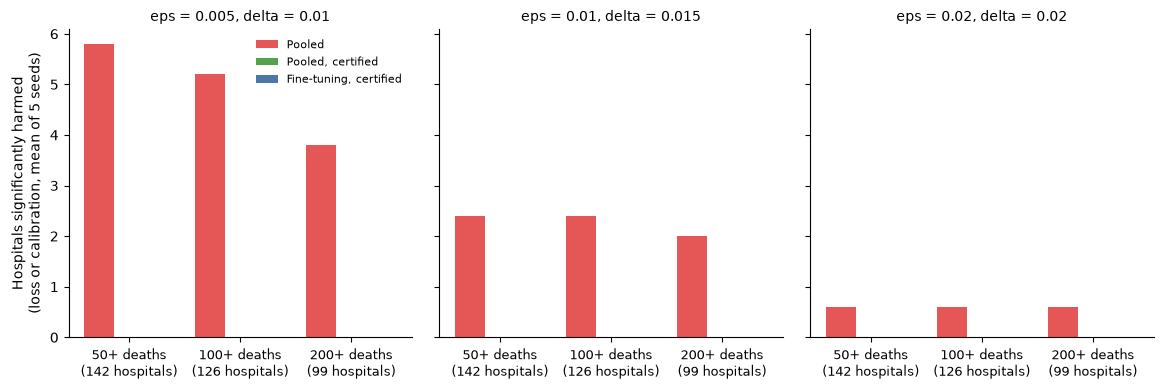

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
seeds = [110, 111, 112, 113, 114]; HEAD = [(0.005, 0.01), (0.01, 0.015), (0.02, 0.02)]
suf = {50: "_cut50", 100: "", 200: "_cut200"}
D = {c: {s: pd.read_csv(f"../outputs/tables/cert_full_seed{s}{suf[c]}.csv").copy() for s in seeds} for c in suf}

def lm(r, pre, eps):
    d, se = r[f"{pre}__diff"].values, r[f"{pre}__se"].values
    z = np.where(se > 0, (d - eps) / np.where(se > 0, se, 1), -np.inf)
    return multipletests(1 - stats.norm.cdf(z), alpha=0.05, method="holm")[0]

rows = []
for cut in suf:
    for eps, delta in HEAD:
        for label, pre in [("Pooled", "pool_full"), ("Pooled, certified", f"cert_pool_e{eps}_d{delta}"), ("Fine-tuning, certified", f"cert_ft_e{eps}_d{delta}")]:
            out = []
            for s in seeds:
                r = D[cut][s]; l = lm(r, pre, eps); c = r[f"{pre}__gaplb"].values > delta
                out.append(dict(hospitals=len(r), either=(l | c).sum(), point_above=(r[f"{pre}__gapmax"] > delta).sum(),
                                nonlocal_=(r[f"{pre}__blend"] > 0).sum() if "cert" in pre else np.nan,
                                mean_loss_diff=r[f"{pre}__diff"].mean(), auroc_gain=(r[f"{pre}__auroc"] - r["local__auroc"]).mean()))
            rows.append({"min_deaths": cut, "eps": eps, "delta": delta, "method": label, **pd.DataFrame(out).mean().to_dict()})
T = pd.DataFrame(rows); T.to_csv("../outputs/tables/T_size_cutoffs.csv", index=False); print(T.round(4).to_string())

fig, ax = plt.subplots(1, 3, figsize=(14, 4.4), sharey=True)
for a, (eps, delta) in zip(ax, HEAD):
    for i, (m, c) in enumerate([("Pooled", "#E45756"), ("Pooled, certified", "#54A24B"), ("Fine-tuning, certified", "#4C78A8")]):
        v = [T[(T.min_deaths == k) & (T.eps == eps) & (T.method == m)].either.values[0] for k in suf]
        a.bar(np.arange(3) + (i - 1) * 0.27, v, 0.27, color=c, label=m)
    n = [int(T[(T.min_deaths == k)].hospitals.iloc[0]) for k in suf]
    a.set_xticks(range(3)); a.set_xticklabels([f"{k}+ deaths\n({n[i]} hospitals)" for i, k in enumerate(suf)], fontsize=9)
    a.set_title(f"eps = {eps}, delta = {delta}", fontsize=10)
ax[0].set_ylabel("Hospitals significantly harmed\n(loss or calibration, mean of 5 seeds)"); ax[0].legend(frameon=False, fontsize=8)
plt.subplots_adjust(wspace=0.08, bottom=0.18)
plt.savefig("../outputs/figures/fig22_size_cutoffs.png", dpi=300); plt.savefig("../outputs/figures/fig22_size_cutoffs.pdf"); plt.show()